## **Forward solve and inversion, averaged over five starting points**

Five tissue conductivities and the two inner interface radii recovered from noisy surface-electrode potentials on a cylindrical limb, by backpropagating through a differentiable multigrid solve.

This notebook runs the same inversion five times from five randomly drawn starting points and reports the mean
recovered value and the mean relative error over those runs. The data is generated once and is identical for every run: the starting point is the only thing that differs, so the spread between runs is the initialisation's doing.

Everything computational is imported from `neuralphysics` and correctness checks are in `tests/`.

In [15]:
# the whole API the experiment needs

import platform
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scipy
import torch

import neuralphysics
from neuralphysics import (
    LIMB,
    SOURCE_SPECS,
    CoefficientHierarchy,
    ElectrodeArray,
    Observation,
    add_measurement_noise,
    configure,
    forward,
    gaussian_dipole,
    grid_at,
    load_geometry,
    true_parameters,
    parameter_names,
    run_ensemble,
    save_geometry,
    sample_initial_parameters,
    thicknesses,
    true_sigma,
    unpack,
    viz,
)

In [16]:
print(configure())
print(f"neuralphysics {neuralphysics.__version__} | torch {torch.__version__} | "
      f"numpy {np.__version__} | scipy {scipy.__version__} | python {platform.python_version()}")
print(f"default dtype {torch.get_default_dtype()} | torch threads {torch.get_num_threads()} | "
      f"{platform.platform()}")

{'dtype': 'torch.float64', 'seed': 42}
neuralphysics 0.1.0 | torch 2.5.1 | numpy 1.26.4 | scipy 1.17.1 | python 3.11.15
default dtype torch.float64 | torch threads 4 | macOS-26.6.1-arm64-arm-64bit


In [17]:
# the forward experiment
# anything not named here is at the package default
# L = 1, z_zeta = 1, coarsening floor of 9, jacobi damping factor omega = 2/3, nu = (2, 2)
# 50 base iterations, and 100% electrode coverage on the four lateral faces

N = 65 # nodes per axis; N = 2^k + 1 must hold for the v-cycle to work
NUM_CYCLES = 8 # fixed budget - not a convergence tolerance
NOISE_PERCENT = 5.0 # noise std as a percentage of the clean field's volume RMS
NOISE_SEED = 0
WIDTH = 0.05 # the 1/e blob radius of a source, a physical length

In [18]:
# the inverse problem

N_RUNS = 5              # inversions, one per drawn starting point
ENSEMBLE_SEED = 12345   # seeds the draws, and nothing else

# the starting points are drawn around the truth: a factor of three either way on
# every conductivity, and 1.5 mm either way on each of the two recovered radii
LOG_SPREAD = np.log(3.0)
RADIUS_SPREAD_MM = 1.5

# the global L-BFGS-B iteration budget for one run, shared across its restarts -
# a restart is handed what is left of this, not a fresh copy of it, so this bounds
# the total work per run. It is a ceiling and not a target: a run that reaches a
# fixed point exits there, at the cost of one extra objective evaluation to find
# out. 200 rather than the 1000 this used to carry because the budget was never
# the binding constraint - the runs were stopping on failed line searches after
# some tens of iterations, and it is the restarts that now carry them further.
MAX_ITERS = 200

# scipy's tolerances are calibrated for O(1) objectives. Here J ~ 1e-5 and
# ||grad J|| ~ 5e-6 near the solution, so the default gtol = 1e-5 is already satisfied
# at the starting point and L-BFGS-B would return after one evaluation having done
# nothing. ftol is relative to max(|f|, 1) = 1, so it is effectively absolute, and the
# default 2.2e-9 would stop while the misfit is still moving in the fourth digit.
FTOL = 1e-16
GTOL = 1e-12

Z_FRACTION = 0.37       # the axial plane the cross-section is drawn on

# where the report picks the figures up, and the stem the per-run geometry files
# are named from. Both live here rather than beside their first use so that the
# cell which redraws the cross-section needs only this cell to have been run: the
# geometry comes off disk, so that figure can be retried after a kernel restart
# without the ensemble in memory.
RESULTS = Path("..") / "experiment-results"
GEOMETRY_STEM = "limb-geometry-run"

LIMB_RADIUS_MM = 24.0   # the physical limb radius, at r/R = 0.5
MM_PER_UNIT = LIMB_RADIUS_MM / 0.5   # normalised radius -> millimetres

In [19]:
# the tissue table - read off the model
print(f"{'layer':8s} {'r/R':>13s} {'thickness':>12s} {'sigma_T':>9s} {'sigma_L':>9s}   source")
r_lo = 0.0
for nm, r_hi in zip(LIMB.layer_names, LIMB.interfaces + (0.5,)):
    sT, sL = LIMB.sigma_layers[nm]
    print(f"{nm:8s} {f'{r_lo:.3f}-{r_hi:.3f}':>13s} "
          f"{(r_hi - r_lo) * LIMB_RADIUS_MM / 0.5:9.2f} mm {sT:9.2f} {sL:9.2f}   "
          f"{'PROVISIONAL' if nm in LIMB.provisional else 'Farina, Mesin, Martina & Merletti (2004)'}")
    r_lo = r_hi

print(f"\nanisotropic layers: {sorted(LIMB.anisotropic_layers)}")
print(f"interface width  epsilon = {LIMB.epsilon:g} of L = {LIMB.epsilon * (N - 1):.2f} h at N = {N}")
print(f"geometry derived from Maksymenko et al. (2023); a {LIMB_RADIUS_MM:.0f} mm limb")

layer              r/R    thickness   sigma_T   sigma_L   source
bone       0.000-0.146      7.00 mm      0.02      0.02   Farina, Mesin, Martina & Merletti (2004)
muscle     0.146-0.417     13.00 mm      0.10      0.50   Farina, Mesin, Martina & Merletti (2004)
fat        0.417-0.479      3.00 mm      0.05      0.05   Farina, Mesin, Martina & Merletti (2004)
skin       0.479-0.500      1.00 mm      1.00      1.00   Farina, Mesin, Martina & Merletti (2004)

anisotropic layers: ['muscle']
interface width  epsilon = 0.00390625 of L = 0.25 h at N = 65
geometry derived from Maksymenko et al. (2023); a 24 mm limb


Two current sources, each a fibre-aligned Gaussian dipole inside muscle.

$W^\top I = 0$ is a necessary condition for the system to have any solution at all: under the insulating Neumann condition the operator has the constants in its null space and $W$ in its left null space, so a source with a net weighted charge is inadmissible. The dipole is balanced by construction and the projection is insurance.

The two sources differ in *radius*, not angle. The limb is rotationally symmetric, so two blobs at the same radius and different azimuths are rotated copies carrying the same information; the radius is what makes them independent, and the pair sits near the inner and outer edges of the band the clearance rule allows so that each is informative about a different interface. The $180^\circ$ separation is for figure legibility only.

In [20]:
# the data: one grid, two sources, one noisy field per source
# generated once at the truth, and identical for every run of the ensemble

grid = grid_at(N)

sources = [gaussian_dipole(grid, LIMB, width=WIDTH, r_blob_norm=r_norm, angle_deg=angle)
           for r_norm, angle in SOURCE_SPECS]

coeff_true = CoefficientHierarchy.from_vectors(LIMB, N)
mask_nodes = ElectrodeArray().mask(grid.n)   # full coverage of the four lateral faces

observations = []
for s, I in enumerate(sources):
    phi_s = forward(I, coeff_true, num_cycles=NUM_CYCLES)
    phi_obs, _ = add_measurement_noise(phi_s, NOISE_PERCENT, NOISE_SEED + s)
    observations.append(Observation(phi=phi_obs, mask=mask_nodes, grid=grid))

### How the starting points are drawn

The optimiser carries $\theta = \log\sigma$ and a pair of softmax logits, so "how far
from the truth" means a *ratio* for a conductivity and a *length* for a radius. The
two draws follow that distinction.

**Conductivities, log-uniform within a factor of three.**
$\sigma^0_i = \sigma_i^{\text{true}}\exp(\varepsilon_i)$ with
$\varepsilon_i \sim U(-\ln 3, \ln 3)$, drawn independently per parameter. $\sigma$ is
a scale parameter, so a factor of three up should be as likely as a factor of three
down, and $\log$ is the coordinate the optimiser actually moves in. Uniform rather
than lognormal because the support is then bounded and every run is a comparable
test: a lognormal concentrates draws near the truth, which flatters the average,
and its tail occasionally produces a start that dominates it. A factor of three is
a deliberate step past the hand-picked start this experiment used previously, which
was within a factor of $2.5$ on every parameter — that start is now an interior
sample rather than a special case.

**Radii, uniform within $\pm 1.5$ mm.** $R^0_k = R_k^{\text{true}} + \delta_k$ with
$\delta_k \sim U(-1.5, 1.5)$ mm, which is $\pm 2$ radial cells at $N = 65$ and one
and a half to three times the offsets of the previous hand-picked start. A radius is
a location, not a scale, so the meaningful perturbation is a length. At this spread
the ordering $0 < R_1 < R_2 < R_{\text{outer}}$ and a non-degenerate layer thickness
hold for every draw — bone $5.5$–$8.5$ mm, muscle $10$–$16$ mm, fat $1.5$–$4.5$ mm —
so no draw is ever rejected and the ensemble is exactly reproducible from its seed.

Two consequences worth stating. The transverse and longitudinal muscle
conductivities are drawn independently, so about $5\%$ of starts have the anisotropy
the wrong way round, $\sigma_L < \sigma_T$; that is a test of the $T$/$L$ split
rather than an accident. And the draws are centred on the truth, which makes this a
basin-of-attraction test and not a prior — it gives every parameter the same
distribution of initial distance, which is what makes an averaged relative error
interpretable.


In [7]:
# the ensemble: draw every starting point up front, then invert from each

starts = sample_initial_parameters(
    LIMB, N_RUNS, seed=ENSEMBLE_SEED,
    log_spread=LOG_SPREAD,
    radius_spread=RADIUS_SPREAD_MM / MM_PER_UNIT,
)

ensemble = run_ensemble(starts, LIMB, N, sources, observations,
                        num_cycles=NUM_CYCLES, max_iters=MAX_ITERS,
                        ftol=FTOL, gtol=GTOL)

# how each run ended. This used to be a check on the iteration count against
# MAX_ITERS, which could not fire: the runs were stopping on failed line searches
# well short of the budget, so a warning keyed to the budget was silent however
# unconverged they were. It is asked of the exit message and of max|g| instead -
# the message says whether the last call stopped on its own criteria or ran out of
# budget, and max|g| says whether the point is stationary at all.

# max|g| is printed rather than only tested. The gradient here is inexact - the
# frozen diagonal in probe_diagonal, and a forward solve on a fixed cycle budget -
# so it has a floor under it that restarting cannot get below, and where that
# floor sits is a result worth reading rather than a pass or a fail.

# best = the lowest final data misfit - we only have the data field in the real world
best = min(range(ensemble.n_runs), key=lambda k: ensemble.loss_histories[k][-1])

print(f"{'run':>4} {'iters':>7} {'restarts':>9} {'max|g|':>10} {'final J':>11}   exit")
for k in range(ensemble.n_runs):
    print(f"{k + 1:>4} {ensemble.n_iterations[k]:>7} {ensemble.n_restarts[k]:>9} "
          f"{ensemble.grad_max[k]:>10.2e} {ensemble.loss_histories[k][-1]:>11.4e}   "
          f"{ensemble.messages[k]}" + ("   <- best" if k == best else ""))

# an iterate that is not first-order stationary is not a minimiser, and averaging
# over one without saying so would misreport the result
stalled = ensemble.unconverged(GTOL)
if stalled:
    print(f"\nWARNING: runs {tuple(k + 1 for k in stalled)} did not reach "
          f"max|g| <= {GTOL:g} - these iterates are not converged minimisers")

 run   iters  restarts     max|g|     final J   exit
   1     112         4   5.46e-10  1.0483e-05   ABNORMAL:    <- best
   2      81         5   1.29e-08  1.0484e-05   CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
   3      80         3   4.56e-10  1.0483e-05   ABNORMAL: 
   4      85         4   5.53e-09  1.0484e-05   ABNORMAL: 
   5      87         5   7.75e-09  1.0485e-05   CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH



In [8]:
# the result: mean recovered value, its spread across the runs, and the mean
# relative error. The mean of the errors, not the error of the mean - the first
# says how wrong a typical run was, and for a parameter recovered from both sides
# the two differ. The spread is a sample standard deviation over the N_RUNS runs -
# how far one run typically lands from the ensemble's answer, which is the part of
# the result the starting point is responsible for - and not the standard error of
# the mean, which is that divided by sqrt(N_RUNS).

sigma_ref = true_sigma(LIMB)
thick_ref = thicknesses(LIMB.interfaces, scale=MM_PER_UNIT)

# a conductivity is quoted to four decimals and a thickness to two: a tenth of a
# micron of muscle is not a claim this experiment is making
values = [(f"{nm} (S/m)", rec, sd, ref, err, ".4f") for nm, rec, sd, ref, err
          in zip(ensemble.param_names, ensemble.mean_sigma, ensemble.std_sigma,
                 sigma_ref, ensemble.mean_sigma_error)]
values += [(f"{nm} (mm)", rec * MM_PER_UNIT, sd * MM_PER_UNIT, ref, err, ".2f")
           for nm, rec, sd, ref, err
           in zip(LIMB.layer_names[:-1], ensemble.mean_thickness,
                  ensemble.std_thickness, thick_ref,
                  ensemble.mean_thickness_error)]   # skin is fixed, so not recovered

# formatted once, so the printed table and the saved figure cannot disagree
HEADERS = ("quantity", "recovered", "std dev", "true", "rel err")
RULE_AFTER = (len(ensemble.param_names) - 1,)   # conductivities above, thicknesses below
CAPTION = (f"mean over {ensemble.n_runs} runs, {NOISE_PERCENT:.1f}% noise\n"
           f"starting points drawn within a factor of {np.exp(LOG_SPREAD):.0f} "
           f"and {RADIUS_SPREAD_MM:.1f} mm of the truth")
table = [(name, format(float(rec), fmt), format(float(sd), fmt),
          format(float(ref), fmt), f"{float(err):.2%}")
         for name, rec, sd, ref, err, fmt in values]

widths = [max(len(h), *(len(row[j]) for row in table)) for j, h in enumerate(HEADERS)]
def as_line(cells):
    return "  ".join(c.ljust(w) if j == 0 else c.rjust(w)
                     for j, (c, w) in enumerate(zip(cells, widths)))

print(CAPTION + "\n")
print(as_line(HEADERS))
print("-" * len(as_line(HEADERS)))
for row in table:
    print(as_line(row))

mean over 5 runs, 5.0% noise
starting points drawn within a factor of 3 and 1.5 mm of the truth

quantity        recovered  std dev    true  rel err
---------------------------------------------------
bone (S/m)         0.0122   0.0038  0.0200   39.20%
muscle_T (S/m)     0.1012   0.0006  0.1000    1.23%
muscle_L (S/m)     0.4833   0.0132  0.5000    3.35%
fat (S/m)          0.0476   0.0007  0.0500    4.84%
skin (S/m)         0.9916   0.0166  1.0000    1.46%
bone (mm)            6.34     0.36    7.00    9.47%
muscle (mm)         13.93     0.53   13.00    7.16%
fat (mm)             2.73     0.17    3.00    8.92%


#### **Conditioning of the linearised problem**

The objective is $J(\theta) = \tfrac12 \|r(\theta)\|^2$ with the residual
$r(\theta) = \big[\,\phi_s(\theta) - \phi_s^{\text{obs}}\,\big]_{s,\,\text{mask}}$,
the difference between predicted and measured potentials stacked over both sources and
restricted to the electrode nodes. Its Jacobian $J_r = \partial r / \partial\theta \in \mathbb{R}^{33280 \times 7}$
is measured below at $\theta = \theta_{\text{true}}$ by central differences.

The seven components of $\theta$ are the coordinates the optimiser moves in, not the physical
parameters: five log-conductivities $\theta_i = \log\sigma_i$, then two softmax logits
$\theta_5 = u_0$, $\theta_6 = u_1$ for the interfaces. The radii must satisfy
$0 < R_1 < R_2 < R_{\text{outer}}$, which L-BFGS-B cannot express as a box, so the layer
thickness *fractions* are optimised through a softmax instead — positive and summing to one,
hence partial sums that increase and stay inside $(0, R_{\text{outer}})$ for any real $u$, with
the outermost recovered layer taken as the reference and its logit pinned at zero to remove the
softmax's shift invariance:

$$d_k = R_k - R_{k-1}, \quad R_0 = 0,\ R_n = R_{\text{outer}}, \qquad
t_k = \frac{d_k}{R_{\text{outer}}}, \qquad
u_i = \log t_{i+1} - \log t_n = \log\frac{d_{i+1}}{d_n}$$

for the $n = 3$ layers inside $R_{\text{outer}}$ and $i = 0, 1$. At the truth
$R = (7, 20, 23)$ mm, so the thicknesses are $d = (7, 13, 3)$ mm — bone, muscle, fat — and the
normalisation cancels in the ratio, leaving millimetres to serve:

$$u_0 = \log\frac{d_1}{d_3} = \log\frac{7}{3} = 0.8473, \qquad
u_1 = \log\frac{d_2}{d_3} = \log\frac{13}{3} = 1.4663$$

The columns below are therefore labelled by $\theta$ and not by the radii: $\theta_i$ is a
one-to-one rescaling of $\sigma_i$ and keeps its name, whereas each logit moves *both* radii at
once — at the truth $\partial R_1/\partial u_1 < 0 < \partial R_2/\partial u_1$ — so no single
radius names that column. Both groups are dimensionless and $O(1)$, which is what makes the
column norms comparable and $\kappa$ independent of a choice of length unit.


In [21]:
# the conditioning of the linearised problem, measured at the truth.
# r(theta) is the stacked masked residual the objective squares, so J_r = dr/dtheta
# is the linear map from a parameter perturbation to the change in the measured
# surface potentials. Its column norms say how visible each parameter is; its
# singular values say which combinations the electrodes can separate.
# Central differences on the residual rather than autograd on the loss: no
# backward pass is needed, and it avoids the frozen-diagonal approximation in the
# V-cycle gradient, so what is measured is the forward map itself.

FD_STEP = 1e-3   # theta is log-sigma and logits, both O(1), so this is a relative step


def masked_residual(theta):
    with torch.no_grad():
        sigma_T, sigma_L, R = unpack(torch.as_tensor(theta), LIMB)
        coeff = CoefficientHierarchy.from_vectors(LIMB, N, sigma_T, sigma_L, interfaces=R)
        return torch.cat([(forward(I, coeff, num_cycles=NUM_CYCLES) - o.phi)[o.mask]
                          for I, o in zip(sources, observations)]).clone()


theta_true = true_parameters(LIMB)

columns = []
for i in range(len(theta_true)):
    step = torch.zeros_like(theta_true)
    step[i] = FD_STEP
    columns.append((masked_residual(theta_true + step)
                    - masked_residual(theta_true - step)) / (2 * FD_STEP))
J_r = torch.stack(columns, dim=1)

singular = torch.linalg.svdvals(J_r)
modes = torch.linalg.svd(J_r, full_matrices=False).Vh
n_sigma_params = len(parameter_names(LIMB))
names = (tuple(parameter_names(LIMB))
         + tuple(f"u_{i}" for i in range(len(theta_true) - n_sigma_params)))

print(f"J_r is {tuple(J_r.shape)}: {J_r.shape[0]} masked potentials against "
      f"{J_r.shape[1]} parameters, linearised at the truth\n")

print(f"{'parameter':>10s}{'||dr/dtheta||':>16s}{'relative to largest':>22s}")
column_norms = J_r.norm(dim=0)
for nm, v in zip(names, column_norms):
    print(f"{nm:>10s}{float(v):16.4e}{float(v / column_norms.max()):22.4f}")

print(f"\nsingular values: " + " ".join(f"{float(s):.3e}" for s in singular))
print(f"condition number: {float(singular[0] / singular[-1]):.1f}")

# the least visible direction, which is the one an unregularised fit leaves to the noise
print(f"\nsmallest singular mode (sigma_min = {float(singular[-1]):.3e}):")
for nm, w in zip(names, modes[-1]):
    if abs(float(w)) > 0.2:
        print(f"  {nm:>10s} {float(w):+.3f}")

J_r is (33280, 7): 33280 masked potentials against 7 parameters, linearised at the truth

 parameter   ||dr/dtheta||   relative to largest
      bone      6.0103e-04                0.0149
  muscle_T      9.9914e-03                0.2470
  muscle_L      4.0457e-02                1.0000
       fat      5.0128e-03                0.1239
      skin      2.0448e-02                0.5054
       u_0      2.8541e-03                0.0705
       u_1      1.1105e-02                0.2745

singular values: 4.703e-02 9.424e-03 2.638e-03 2.034e-03 5.500e-04 2.388e-04 9.639e-05
condition number: 487.9

smallest singular mode (sigma_min = 9.639e-05):
        bone +0.855
         u_1 -0.446


In [22]:
# how each mode is built out of the parameters. modes[k] is a unit vector in
# parameter space, so its squared components partition 1 and read as shares:
# entry (i, k) is the fraction of mode k that parameter i accounts for. Reading
# down a column describes a mode; reading across a row says where a parameter's
# influence sits in the spectrum, and a row weighted towards the right-hand
# columns is a parameter the electrodes struggle to see.

share = modes.T ** 2          # (parameter, mode)

print("\nparameter composition of each mode, as a share of the mode's squared length")
print(f"{'':10s}" + "".join(f"{f'mode {k}':>9s}" for k in range(len(singular)))
      + f"{'row sum':>10s}")
print(f"{'sv/sv_max':>10s}"
      + "".join(f"{float(s / singular[0]):9.4f}" for s in singular))
print("-" * (10 + 9 * len(singular) + 10))
for nm, row in zip(names, share):
    print(f"{nm:10s}" + "".join(f"{float(v):9.4f}" for v in row)
          + f"{float(row.sum()):10.4f}")


parameter composition of each mode, as a share of the mode's squared length
             mode 0   mode 1   mode 2   mode 3   mode 4   mode 5   mode 6   row sum
 sv/sv_max   1.0000   0.2004   0.0561   0.0433   0.0117   0.0051   0.0020
-----------------------------------------------------------------------------------
bone         0.0001   0.0001   0.0045   0.0147   0.1844   0.0657   0.7305    1.0000
muscle_T     0.0259   0.4482   0.3039   0.1438   0.0007   0.0748   0.0026    1.0000
muscle_L     0.7381   0.0405   0.1334   0.0041   0.0337   0.0266   0.0236    1.0000
fat          0.0086   0.0497   0.1063   0.2092   0.0351   0.5634   0.0278    1.0000
skin         0.1704   0.4523   0.1542   0.0110   0.0103   0.1901   0.0118    1.0000
u_0          0.0015   0.0051   0.2956   0.5481   0.0663   0.0789   0.0044    1.0000
u_1          0.0554   0.0040   0.0022   0.0690   0.6695   0.0006   0.1993    1.0000


#### **The directions the data resolve**

Noise of relative size $\eta$ swamps a singular direction once $\sigma_i / \sigma_{\max} < \eta$,
since a perturbation along $v_i$ moves the data by $\sigma_i$ while the noise floor sits at
$\eta\,\sigma_{\max}$. Counting the directions above that threshold separates a genuine loss of
information from a numerical one: $\kappa \ll 1/\varepsilon_{\text{mach}}$ rules out the latter.

In [14]:
# kappa is only interpretable against the noise level: a direction is noise-dominated
# once sigma_max / sigma_i exceeds 1 / eta, so the relative data error eta is amplified
# to order one in that direction. That eta is the electrode-level relative error, not
# NOISE_PERCENT / 100 -- the noise is specified against the volume RMS, so the realised
# error on the masked data is larger. At the truth the residual is exactly minus the
# noise on the mask, so it is recoverable here without re-solving. J_r stacks both
# sources, so this eta is the stacked one.
r0 = masked_residual(theta_true)
phi_obs_masked = torch.cat([o.phi[o.mask] for o in observations])
eta = float(r0.norm() / (phi_obs_masked + r0).norm())

resolved = int((singular / singular[0] > eta).sum())
print(f"\neta_vol = {NOISE_PERCENT / 100:.3g} specified against the volume RMS; "
      f"realised electrode-level error eta_M = {eta:.3g}")
print(f"  directions are resolved while sigma_i / sigma_max > {eta:.3g}")
print(f"  {resolved} of {len(singular)} directions resolved; "
      f"kappa = {float(singular[0] / singular[-1]):.1f} against the 1/eta = {1 / eta:.0f} threshold")
print(f"  far from the float64 limit (~1e16), so this is not a numerical failure - "
      f"the weakest direction is noise-limited, not solver-limited")


eta_vol = 0.05 specified against the volume RMS; realised electrode-level error eta_M = 0.0931
  directions are resolved while sigma_i / sigma_max > 0.0931
  2 of 7 directions resolved; kappa = 487.9 against the 1/eta = 11 threshold
  far from the float64 limit (~1e16), so this is not a numerical failure - the weakest direction is noise-limited, not solver-limited


misfit at the truth: J = 1.0485e-05


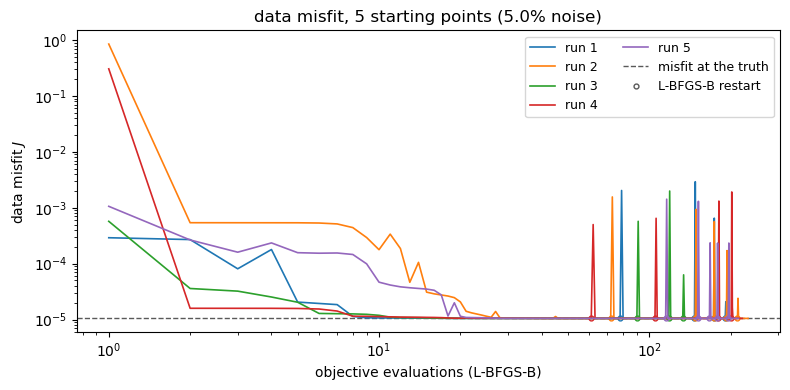

In [11]:
# the misfit at the true parameters: what the objective is worth when the
# parameters are recovered exactly and the only thing left in the residual is the
# measurement noise. No inversion of this data can go below it, so it is the floor
# the runs are descending towards, and the distance between a curve and it is the
# part of the misfit that is still model error rather than noise. masked_residual
# and theta_true are the ones defined for the conditioning measurement above, so
# this is the same residual the objective squares - one extra forward solve per
# source, and nothing here is a second opinion on what J means.
J_floor = 0.5 * float(masked_residual(theta_true).pow(2).sum())
print(f"misfit at the truth: J = {J_floor:.4e}")

# log-log, with the floor drawn and the restarts marked. The descent happens in
# the first few tens of evaluations and the runs then sit at the floor for several
# hundred more, so a linear abscissa spends almost all of its width on the part
# where nothing moves. Nothing is dropped or rescaled to fix that - the same
# points are drawn at the same values - the compression just falls on the plateau
# instead of on the descent. The restart markers matter for reading the flat
# stretches: the misfit is flat across a restart by construction, because the next
# call re-evaluates the point it was handed, and the evaluations just before one
# are a line search failing to find a decrease. Neither is a stall.
fig_misfit = viz.plot_ensemble_misfit(ensemble.loss_histories,
                                     noise_percent=NOISE_PERCENT,
                                     floor=J_floor,
                                     restart_at=ensemble.restart_at)

In [12]:
# the geometry histories, written to disk so the cross-section figure can be
# redrawn without rerunning the inversion. This experiment takes long enough that
# the panel spacing cannot be chosen by trial against a live kernel, and the
# spacing is what decides whether the figure reads at the size the report prints
# it. Drawing is the next cell's job, and it reads these files rather than the
# ensemble.
#
# Every run is written, not only the one drawn. A geometry history is seven
# scalars an iterate, so all five together are a few tens of kilobytes, and that
# is nothing set against rerunning the ensemble because the run worth showing
# turned out to be a different one.

for k, snapshots in enumerate(ensemble.geometries):
    written = save_geometry(RESULTS / f"{GEOMETRY_STEM}{k + 1}", snapshots,
                            n=N, run=k + 1, is_best=int(k == best),
                            final_misfit=float(ensemble.loss_histories[k][-1]))
    print(f"run {k + 1}: {len(snapshots):>5} iterates -> {written.name}"
          + ("   <- best" if k == best else ""))

run 1:   209 iterates -> limb-geometry-run1.npz   <- best
run 2:   232 iterates -> limb-geometry-run2.npz
run 3:   150 iterates -> limb-geometry-run3.npz
run 4:   221 iterates -> limb-geometry-run4.npz
run 5:   214 iterates -> limb-geometry-run5.npz


run 1 on a 65^3 grid, final misfit 1.0483e-05
209 iterates recorded, drawing every 21 -> 11 panels including the truth
the figure refuses over 24 panels, so snapshot_every=10 is about as fine as this run can be drawn


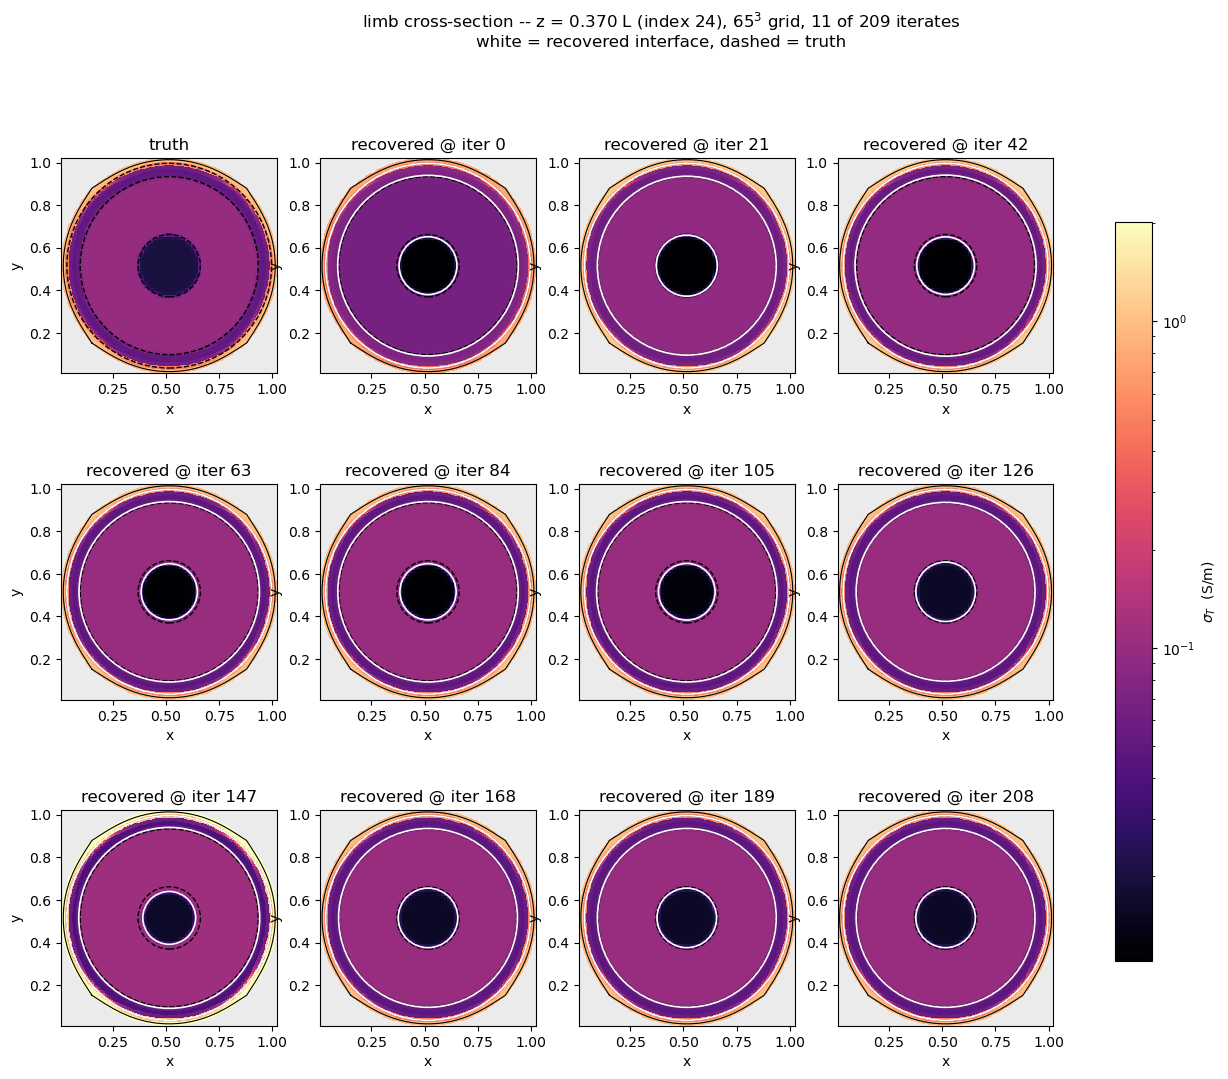

In [26]:
# the recovered limb cross-section, redrawn from disk. Nothing in this cell reads
# the ensemble, so it can be run on its own -- after a kernel restart, or a week
# later -- as many times as it takes to find a spacing that reads in print. The
# inversion is the expensive part and it has already happened; which iterates get
# drawn is a decision about the figure and is made here.

GEOMETRY_RUN = 1     # which run to draw, numbered as the cell above printed them
GEOMETRY_EVERY = 21   # draw every k-th recorded iterate; None draws every one

snapshots, geometry_meta = load_geometry(RESULTS / f"{GEOMETRY_STEM}{GEOMETRY_RUN}")

# the grid the run was made on, taken from the file rather than from N. The two
# are the same while the notebook is run start to finish, and are not the same the
# moment N is changed and this cell is run against an older file.
grid_drawn = grid_at(geometry_meta["n"])

fig_geometry = viz.plot_geometry_panels(grid_drawn, LIMB, snapshots, LIMB.epsilon,
                                        z_fraction=Z_FRACTION,
                                        snapshot_every=GEOMETRY_EVERY)

drawn = len(snapshots[::GEOMETRY_EVERY]) if GEOMETRY_EVERY else len(snapshots)
floor_every = -(-len(snapshots) // viz.MAX_GEOMETRY_PANELS) + 1
print(f"run {GEOMETRY_RUN} on a {geometry_meta['n']}^3 grid, final misfit "
      f"{geometry_meta['final_misfit']:.4e}"
      + ("" if geometry_meta["is_best"] else "   (not the best run of the ensemble)"))
print(f"{len(snapshots)} iterates recorded, drawing every {GEOMETRY_EVERY} "
      f"-> {1 + drawn} panels including the truth")
print(f"the figure refuses over {viz.MAX_GEOMETRY_PANELS} panels, so "
      f"snapshot_every={floor_every} is about as fine as this run can be drawn")

In [27]:
# where each run started - the drawn conductivities and layer thicknesses - and
# which start the best run came from. best is the run already identified above:
# the lowest final data misfit, which is judged without reference to the truth.
# Skin is absent because its thickness is fixed, not drawn.

layers = LIMB.layer_names[:-1]
n_sigma = len(ensemble.param_names)

print(f"{'run':>4}  " + "".join(f"{nm:>10s}" for nm in ensemble.param_names)
      + "   " + "".join(f"{nm:>10s}" for nm in layers))
print(f"{'':>4}  " + "".join(f"{'(S/m)':>10s}" for _ in ensemble.param_names)
      + "   " + "".join(f"{'(mm)':>10s}" for _ in layers))

for k, theta_0 in enumerate(starts):
    _, _, R_0 = unpack(theta_0, LIMB)
    print(f"{k + 1:>4}  "
          + "".join(f"{float(v):10.4f}" for v in theta_0[:n_sigma].exp())
          + "   " + "".join(f"{float(v):10.2f}"
                            for v in thicknesses(R_0, scale=MM_PER_UNIT)[:-1])
          + ("   <- best" if k == best else ""))

print(f"{'true':>4}  " + "".join(f"{float(v):10.4f}" for v in true_sigma(LIMB))
      + "   " + "".join(f"{float(v):10.2f}"
                        for v in thicknesses(LIMB.interfaces, scale=MM_PER_UNIT)[:-1]))

 run        bone  muscle_T  muscle_L       fat      skin         bone    muscle       fat
           (S/m)     (S/m)     (S/m)     (S/m)     (S/m)         (mm)      (mm)      (mm)
   1      0.0110    0.0669    0.9610    0.0736    0.7872         6.50     13.80      2.71   <- best
   2      0.0100    0.1462    1.3199    0.0288    2.6813         7.50     11.29      4.21
   3      0.0176    0.2338    0.7716    0.0341    1.6720         6.16     12.58      4.26
   4      0.0095    0.0704    0.4632    0.0299    2.0014         6.08     12.81      4.11
   5      0.0082    0.1242    1.0901    0.0625    2.5836         7.67     13.41      1.92
true      0.0200    0.1000    0.5000    0.0500    1.0000         7.00     13.00      3.00


In [28]:
# the three deliverables, saved where the report picks them up

RESULTS = Path("..") / "experiment-results"

fig_misfit.savefig(RESULTS / "average-data-misfit.png", dpi=200, bbox_inches="tight")

fig_geometry.savefig(RESULTS / "limb-cross-section-recovery.png", dpi=200,
                     bbox_inches="tight")

fig_table = viz.plot_table(HEADERS, table, title=CAPTION, rule_after=RULE_AFTER)
fig_table.savefig(RESULTS / "average-parameter-recovery.png", dpi=200,
                  bbox_inches="tight")
plt.close(fig_table)   # the printed table above is this notebook's copy of it

print(f"saved to {RESULTS.resolve()}")

saved to ./experiment-results
